In [1]:
import pandas as pd

# load dataset
df = pd.read_csv("nyc_taxi_2024-01.csv")

# quick check
df.head()

C:\Users\pc\AppData\Local\Temp\ipykernel_10780\2585382361.py:4: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("nyc_taxi_2024-01.csv")


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


In [2]:
print(df.shape)
print(df.columns)

df.head()

(2964624, 19)
Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag',
       'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra',
       'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge',
       'total_amount', 'congestion_surcharge', 'Airport_fee'],
      dtype='object')


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


In [4]:
# checking data types
df.dtypes

VendorID                   int64
tpep_pickup_datetime      object
tpep_dropoff_datetime     object
passenger_count          float64
trip_distance            float64
RatecodeID               float64
store_and_fwd_flag        object
PULocationID               int64
DOLocationID               int64
payment_type               int64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport_fee              float64
dtype: object

Two datetime columns are stored as object instead of proper datetime

In [5]:
# checking missing values
df.isna().sum()

VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          140162
trip_distance                 0
RatecodeID               140162
store_and_fwd_flag       140162
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   0
extra                         0
mta_tax                       0
tip_amount                    0
tolls_amount                  0
improvement_surcharge         0
total_amount                  0
congestion_surcharge     140162
Airport_fee              140162
dtype: int64

In [6]:
# converting pickup and dropoff columns to proper datetime format
df["tpep_pickup_datetime"] = pd.to_datetime(df["tpep_pickup_datetime"], errors="coerce")
df["tpep_dropoff_datetime"] = pd.to_datetime(df["tpep_dropoff_datetime"], errors="coerce")

# check the result
df[["tpep_pickup_datetime", "tpep_dropoff_datetime"]].dtypes

tpep_pickup_datetime     datetime64[ns]
tpep_dropoff_datetime    datetime64[ns]
dtype: object

In [8]:
# checking whether any datetime values became missing after conversion
df[["tpep_pickup_datetime", "tpep_dropoff_datetime"]].isna().sum()

tpep_pickup_datetime     0
tpep_dropoff_datetime    0
dtype: int64

In [9]:
# creating trip duration in minutes
df["trip_duration_min"] = (
    (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
)

# summary
df["trip_duration_min"].describe()

count    2.964624e+06
mean     1.561295e+01
std      3.485105e+01
min     -1.356667e+01
25%      7.150000e+00
50%      1.163333e+01
75%      1.868333e+01
max      9.455400e+03
Name: trip_duration_min, dtype: float64

In [10]:
# counting potentially invalid trips
print("Negative duration trips:", (df["trip_duration_min"] < 0).sum())
print("Zero duration trips:", (df["trip_duration_min"] == 0).sum())

# Checking very long trips
print("Trips longer than 180 minutes:", (df["trip_duration_min"] > 180).sum())

Negative duration trips: 56
Zero duration trips: 814
Trips longer than 180 minutes: 1983


In [11]:
# checking key numeric columns
numeric_cols = ["trip_distance", "fare_amount", "total_amount", "tip_amount"]

df[numeric_cols].describe()

,trip_distance,fare_amount,total_amount,tip_amount
count,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06
mean,3.652169e+00,1.817506e+01,2.680150e+01,3.335870e+00
std,2.254626e+02,1.894955e+01,2.338558e+01,3.896551e+00
min,0.000000e+00,-8.990000e+02,-9.000000e+02,-8.000000e+01
25%,1.000000e+00,8.600000e+00,1.538000e+01,1.000000e+00
50%,1.680000e+00,1.280000e+01,2.010000e+01,2.700000e+00
75%,3.110000e+00,2.050000e+01,2.856000e+01,4.120000e+00
max,3.127223e+05,5.000000e+03,5.000000e+03,4.280000e+02


In [12]:
# counting suspicious values
print("Negative trip distance:", (df["trip_distance"] < 0).sum())
print("Zero trip distance:", (df["trip_distance"] == 0).sum())

print("Negative fare amount:", (df["fare_amount"] < 0).sum())
print("Zero fare amount:", (df["fare_amount"] == 0).sum())

print("Negative total amount:", (df["total_amount"] < 0).sum())
print("Zero total amount:", (df["total_amount"] == 0).sum())

print("Negative tip amount:", (df["tip_amount"] < 0).sum())

Negative trip distance: 0
Zero trip distance: 60371
Negative fare amount: 37448
Zero fare amount: 893
Negative total amount: 35504
Zero total amount: 416
Negative tip amount: 102


In [13]:
# making a cleaned copy
df_clean = df.copy()

# keeping only trips with sensible core values
df_clean = df_clean[
    (df_clean["trip_duration_min"] > 0) &
    (df_clean["trip_distance"] >= 0) &
    (df_clean["fare_amount"] >= 0) &
    (df_clean["total_amount"] >= 0) &
    (df_clean["tip_amount"] >= 0)
]

# new shape
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)
print("Rows removed:", df.shape[0] - df_clean.shape[0])

Original shape: (2964624, 20)
Cleaned shape: (2926190, 20)
Rows removed: 38434


In [14]:
print("Negative duration trips:", (df_clean["trip_duration_min"] < 0).sum())
print("Zero duration trips:", (df_clean["trip_duration_min"] == 0).sum())
print("Negative fare amount:", (df_clean["fare_amount"] < 0).sum())
print("Negative total amount:", (df_clean["total_amount"] < 0).sum())
print("Negative tip amount:", (df_clean["tip_amount"] < 0).sum())

Negative duration trips: 0
Zero duration trips: 0
Negative fare amount: 0
Negative total amount: 0
Negative tip amount: 0


In [15]:
# extracting/making time-based features from pickup datetime
df_clean["pickup_hour"] = df_clean["tpep_pickup_datetime"].dt.hour
df_clean["pickup_dayofweek"] = df_clean["tpep_pickup_datetime"].dt.dayofweek
df_clean["pickup_month"] = df_clean["tpep_pickup_datetime"].dt.month

# weekend indicator (1 = weekend, 0 = weekday)
df_clean["is_weekend"] = df_clean["pickup_dayofweek"].isin([5, 6]).astype(int)

# check
df_clean[["pickup_hour", "pickup_dayofweek", "pickup_month", "is_weekend"]].head()

,pickup_hour,pickup_dayofweek,pickup_month,is_weekend
0,0,0,1,0
1,0,0,1,0
2,0,0,1,0
3,0,0,1,0
4,0,0,1,0


In [17]:
df_clean["pickup_hour"].unique()

array([ 0, 23,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15,
       16, 17, 18, 22, 19, 20, 21], dtype=int32)

## Filtering Manhattan Zones

In [18]:
# list of Manhattan taxi zone IDs (maybe use the lookup table, need to download the csv file (not provided))
manhattan_zones = [
    4, 12, 13, 24, 41, 42, 43, 45, 48, 50,
    68, 74, 75, 79, 87, 88, 90, 100, 107, 113,
    114, 116, 120, 125, 137, 140, 141, 142, 143,
    144, 148, 151, 152, 158, 161, 162, 163, 164,
    166, 170, 186, 194, 202, 209, 211, 224, 229,
    230, 231, 232, 233, 234, 236, 237, 238, 239,
    246, 249, 261, 262, 263
]

In [19]:
df_manhattan = df_clean[df_clean["PULocationID"].isin(manhattan_zones)].copy()

# result
print("Original rows:", df_clean.shape[0])
print("Manhattan rows:", df_manhattan.shape[0])

Original rows: 2926190
Manhattan rows: 2613102


# Zone-hour dataset

In [21]:
# creating a datetime rounded to the hour
df_manhattan["pickup_hour_dt"] = df_manhattan["tpep_pickup_datetime"].dt.floor("h")

# aggregating to zone-hour level
df_zone_hour = df_manhattan.groupby(
    ["PULocationID", "pickup_hour_dt"]
).agg(
    trip_count=("VendorID", "count"), # DEMAND VARIABLE (IMPORTANT)
    total_revenue=("total_amount", "sum"),
    avg_fare=("fare_amount", "mean"),
    avg_distance=("trip_distance", "mean")
).reset_index()

# result
df_zone_hour.head()

,PULocationID,pickup_hour_dt,trip_count,total_revenue,avg_fare,avg_distance
0,4,2024-01-01 00:00:00,24,706.85,21.317500,2.858333
1,4,2024-01-01 01:00:00,28,899.90,23.826429,3.604286
2,4,2024-01-01 02:00:00,33,1081.76,24.791212,3.551515
3,4,2024-01-01 03:00:00,31,1087.81,27.201935,3.998065
4,4,2024-01-01 04:00:00,31,709.24,17.365161,2.675161


## IMPORTANT: trip_count and total_revenue are the target variable now

In [23]:
df_zone_hour.describe()
df_zone_hour.shape

(40965, 6)

right now our dataset only includes hours where trips occurred
but we also need:
hours with zero demand

In [30]:
# restricting to January 2024 only
df_manhattan = df_manhattan[
    (df_manhattan["tpep_pickup_datetime"] >= "2024-01-01") &
    (df_manhattan["tpep_pickup_datetime"] < "2024-02-01")
].copy()

# check new min/max
print(df_manhattan["tpep_pickup_datetime"].min())
print(df_manhattan["tpep_pickup_datetime"].max())

2024-01-01 00:00:00
2024-01-31 23:59:55


In [31]:
df_manhattan["pickup_hour_dt"] = df_manhattan["tpep_pickup_datetime"].dt.floor("h")

In [32]:
df_zone_hour = df_manhattan.groupby(
    ["PULocationID", "pickup_hour_dt"]
).agg(
    trip_count=("VendorID", "count"),
    total_revenue=("total_amount", "sum")
).reset_index()

In [33]:
all_hours = pd.date_range(
    start="2024-01-01",
    end="2024-01-31 23:00:00",
    freq="h"
)

In [34]:
all_zones = sorted(df_manhattan["PULocationID"].unique())

full_index = pd.MultiIndex.from_product(
    [all_zones, all_hours],
    names=["PULocationID", "pickup_hour_dt"]
)

df_zone_hour_full = (
    df_zone_hour
    .set_index(["PULocationID", "pickup_hour_dt"])
    .reindex(full_index)
    .reset_index()
)

# fill targets
df_zone_hour_full["trip_count"] = df_zone_hour_full["trip_count"].fillna(0)
df_zone_hour_full["total_revenue"] = df_zone_hour_full["total_revenue"].fillna(0)

In [37]:
df_zone_hour_full.shape

(45384, 4)

In [36]:
df_zone_hour_full.head()

,PULocationID,pickup_hour_dt,trip_count,total_revenue
0,4,2024-01-01 00:00:00,24.0,706.85
1,4,2024-01-01 01:00:00,28.0,899.90
2,4,2024-01-01 02:00:00,33.0,1081.76
3,4,2024-01-01 03:00:00,31.0,1087.81
4,4,2024-01-01 04:00:00,31.0,709.24


In [38]:
df_zone_hour_full.describe()

,PULocationID,pickup_hour_dt,trip_count,total_revenue
count,45384.000000,45384,45384.000000,45384.000000
mean,146.983607,2024-01-16 11:30:00,57.577296,1316.010039
min,4.000000,2024-01-01 00:00:00,0.000000,0.000000
25%,88.000000,2024-01-08 17:45:00,4.000000,118.117500
50%,148.000000,2024-01-16 11:30:00,23.000000,575.395000
75%,224.000000,2024-01-24 05:15:00,84.000000,1877.222500
max,263.000000,2024-01-31 23:00:00,723.000000,17597.530000
std,73.860559,NaN,78.692267,1782.858559


In [39]:
# create time features from the hourly datetime
df_zone_hour_full["hour"] = df_zone_hour_full["pickup_hour_dt"].dt.hour
df_zone_hour_full["dayofweek"] = df_zone_hour_full["pickup_hour_dt"].dt.dayofweek
df_zone_hour_full["month"] = df_zone_hour_full["pickup_hour_dt"].dt.month
df_zone_hour_full["day"] = df_zone_hour_full["pickup_hour_dt"].dt.day

# weekend flag
df_zone_hour_full["is_weekend"] = df_zone_hour_full["dayofweek"].isin([5, 6]).astype(int)

# check
df_zone_hour_full.head()

,PULocationID,pickup_hour_dt,trip_count,total_revenue,hour,dayofweek,month,day,is_weekend
0,4,2024-01-01 00:00:00,24.0,706.85,0,0,1,1,0
1,4,2024-01-01 01:00:00,28.0,899.90,1,0,1,1,0
2,4,2024-01-01 02:00:00,33.0,1081.76,2,0,1,1,0
3,4,2024-01-01 03:00:00,31.0,1087.81,3,0,1,1,0
4,4,2024-01-01 04:00:00,31.0,709.24,4,0,1,1,0


In [40]:
df_zone_hour_full["day"].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31],
      dtype=int32)

In [41]:
df_zone_hour_full[["pickup_hour_dt", "hour", "dayofweek", "day", "month", "is_weekend"]].head()

,pickup_hour_dt,hour,dayofweek,day,month,is_weekend
0,2024-01-01 00:00:00,0,0,1,1,0
1,2024-01-01 01:00:00,1,0,1,1,0
2,2024-01-01 02:00:00,2,0,1,1,0
3,2024-01-01 03:00:00,3,0,1,1,0
4,2024-01-01 04:00:00,4,0,1,1,0


## Lag features

In [42]:
# sorting first so lags are created in the right order
df_zone_hour_full = df_zone_hour_full.sort_values(["PULocationID", "pickup_hour_dt"])

# lag features for trip_count
df_zone_hour_full["trip_count_lag_1"] = df_zone_hour_full.groupby("PULocationID")["trip_count"].shift(1)
df_zone_hour_full["trip_count_lag_24"] = df_zone_hour_full.groupby("PULocationID")["trip_count"].shift(24)

# lag features for total_revenue
df_zone_hour_full["total_revenue_lag_1"] = df_zone_hour_full.groupby("PULocationID")["total_revenue"].shift(1)
df_zone_hour_full["total_revenue_lag_24"] = df_zone_hour_full.groupby("PULocationID")["total_revenue"].shift(24)

# check
df_zone_hour_full.head(30)

,PULocationID,pickup_hour_dt,trip_count,total_revenue,hour,dayofweek,month,day,is_weekend,trip_count_lag_1,trip_count_lag_24,total_revenue_lag_1,total_revenue_lag_24
0,4,2024-01-01 00:00:00,24.0,706.85,0,0,1,1,0,NaN,NaN,NaN,NaN
1,4,2024-01-01 01:00:00,28.0,899.90,1,0,1,1,0,24.0,NaN,706.85,NaN
2,4,2024-01-01 02:00:00,33.0,1081.76,2,0,1,1,0,28.0,NaN,899.90,NaN
3,4,2024-01-01 03:00:00,31.0,1087.81,3,0,1,1,0,33.0,NaN,1081.76,NaN
4,4,2024-01-01 04:00:00,31.0,709.24,4,0,1,1,0,31.0,NaN,1087.81,NaN
5,4,2024-01-01 05:00:00,7.0,169.47,5,0,1,1,0,31.0,NaN,709.24,NaN
6,4,2024-01-01 06:00:00,6.0,147.72,6,0,1,1,0,7.0,NaN,169.47,NaN
7,4,2024-01-01 07:00:00,4.0,91.36,7,0,1,1,0,6.0,NaN,147.72,NaN
8,4,2024-01-01 08:00:00,0.0,0.00,8,0,1,1,0,4.0,NaN,91.36,NaN
9,4,2024-01-01 09:00:00,1.0,12.58,9,0,1,1,0,0.0,NaN,0.00,NaN


In [43]:
# rolling mean for trip_count (past 3 hours)
df_zone_hour_full["trip_count_roll_3"] = (
    df_zone_hour_full.groupby("PULocationID")["trip_count"]
    .rolling(window=3)
    .mean()
    .reset_index(level=0, drop=True)
)

# rolling mean for trip_count (past 24 hours)
df_zone_hour_full["trip_count_roll_24"] = (
    df_zone_hour_full.groupby("PULocationID")["trip_count"]
    .rolling(window=24)
    .mean()
    .reset_index(level=0, drop=True)
)

# rolling mean for revenue
df_zone_hour_full["revenue_roll_3"] = (
    df_zone_hour_full.groupby("PULocationID")["total_revenue"]
    .rolling(window=3)
    .mean()
    .reset_index(level=0, drop=True)
)

df_zone_hour_full["revenue_roll_24"] = (
    df_zone_hour_full.groupby("PULocationID")["total_revenue"]
    .rolling(window=24)
    .mean()
    .reset_index(level=0, drop=True)
)

# check
df_zone_hour_full.head(30)

,PULocationID,pickup_hour_dt,trip_count,total_revenue,hour,dayofweek,month,day,is_weekend,trip_count_lag_1,trip_count_lag_24,total_revenue_lag_1,total_revenue_lag_24,trip_count_roll_3,trip_count_roll_24,revenue_roll_3,revenue_roll_24
0,4,2024-01-01 00:00:00,24.0,706.85,0,0,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4,2024-01-01 01:00:00,28.0,899.90,1,0,1,1,0,24.0,NaN,706.85,NaN,NaN,NaN,NaN,NaN
2,4,2024-01-01 02:00:00,33.0,1081.76,2,0,1,1,0,28.0,NaN,899.90,NaN,28.333333,NaN,896.170000,NaN
3,4,2024-01-01 03:00:00,31.0,1087.81,3,0,1,1,0,33.0,NaN,1081.76,NaN,30.666667,NaN,1023.156667,NaN
4,4,2024-01-01 04:00:00,31.0,709.24,4,0,1,1,0,31.0,NaN,1087.81,NaN,31.666667,NaN,959.603333,NaN
5,4,2024-01-01 05:00:00,7.0,169.47,5,0,1,1,0,31.0,NaN,709.24,NaN,23.000000,NaN,655.506667,NaN
6,4,2024-01-01 06:00:00,6.0,147.72,6,0,1,1,0,7.0,NaN,169.47,NaN,14.666667,NaN,342.143333,NaN
7,4,2024-01-01 07:00:00,4.0,91.36,7,0,1,1,0,6.0,NaN,147.72,NaN,5.666667,NaN,136.183333,NaN
8,4,2024-01-01 08:00:00,0.0,0.00,8,0,1,1,0,4.0,NaN,91.36,NaN,3.333333,NaN,79.693333,NaN
9,4,2024-01-01 09:00:00,1.0,12.58,9,0,1,1,0,0.0,NaN,0.00,NaN,1.666667,NaN,34.646667,NaN


# EDA for new dataset

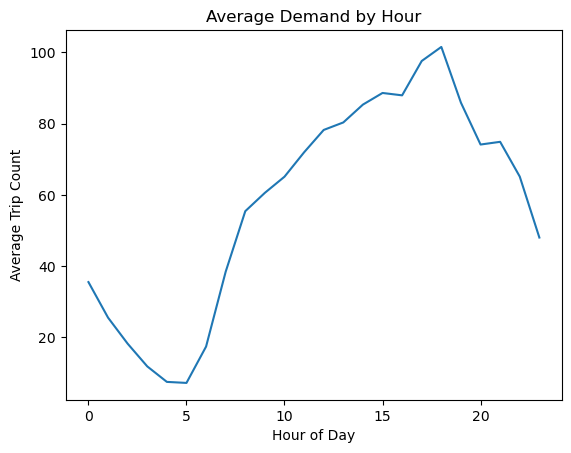

In [44]:
import matplotlib.pyplot as plt

# average demand by hour
hourly_demand = df_zone_hour_full.groupby("hour")["trip_count"].mean()

plt.figure()
hourly_demand.plot()
plt.title("Average Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Trip Count")
plt.show()

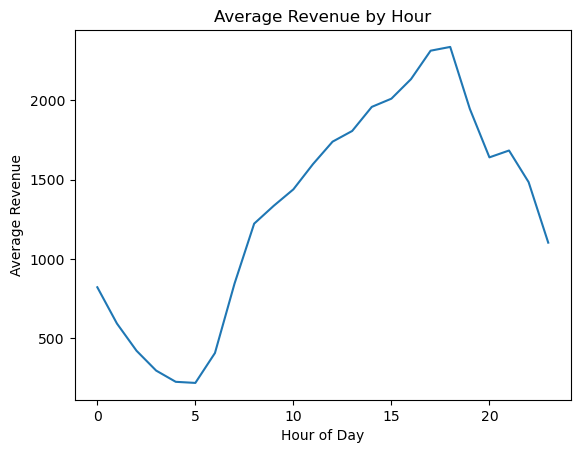

In [45]:
hourly_revenue = df_zone_hour_full.groupby("hour")["total_revenue"].mean()

plt.figure()
hourly_revenue.plot()
plt.title("Average Revenue by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Revenue")
plt.show()

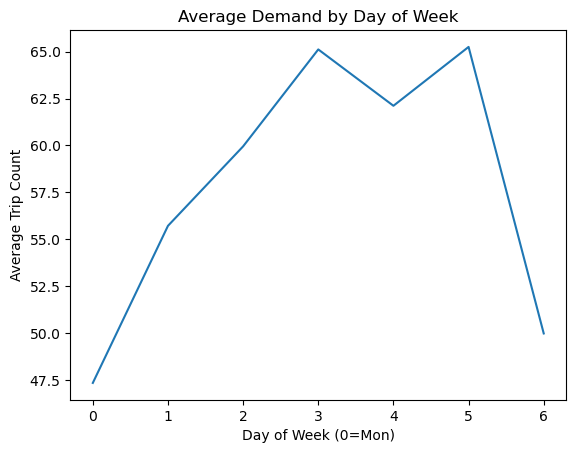

In [46]:
dow_demand = df_zone_hour_full.groupby("dayofweek")["trip_count"].mean()

plt.figure()
dow_demand.plot()
plt.title("Average Demand by Day of Week")
plt.xlabel("Day of Week (0=Mon)")
plt.ylabel("Average Trip Count")
plt.show()

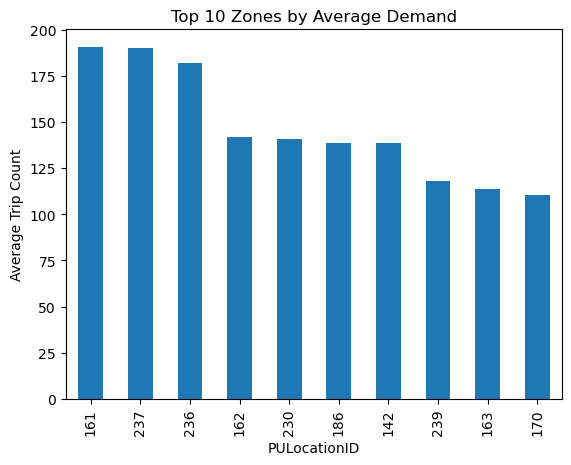

In [47]:
top_zones = df_zone_hour_full.groupby("PULocationID")["trip_count"].mean().sort_values(ascending=False).head(10)

top_zones.plot(kind="bar")
plt.title("Top 10 Zones by Average Demand")
plt.ylabel("Average Trip Count")
plt.show()

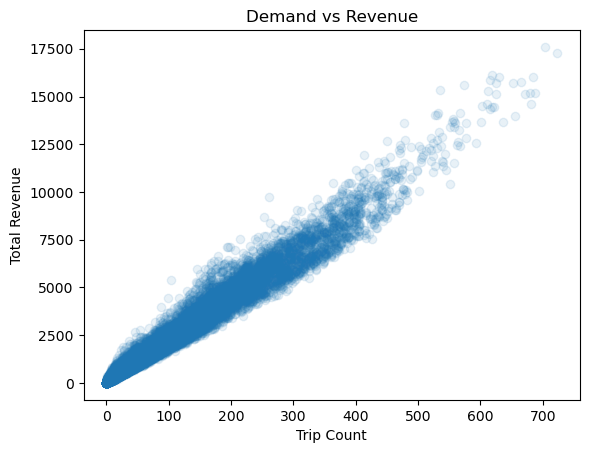

In [48]:
plt.scatter(df_zone_hour_full["trip_count"], df_zone_hour_full["total_revenue"], alpha=0.1)
plt.xlabel("Trip Count")
plt.ylabel("Total Revenue")
plt.title("Demand vs Revenue")
plt.show()

In [49]:
print(df_zone_hour_full.shape)
print(df_zone_hour_full.columns)
print(df_zone_hour_full.dtypes)

(45384, 17)
Index(['PULocationID', 'pickup_hour_dt', 'trip_count', 'total_revenue', 'hour',
       'dayofweek', 'month', 'day', 'is_weekend', 'trip_count_lag_1',
       'trip_count_lag_24', 'total_revenue_lag_1', 'total_revenue_lag_24',
       'trip_count_roll_3', 'trip_count_roll_24', 'revenue_roll_3',
       'revenue_roll_24'],
      dtype='object')
PULocationID                     int64
pickup_hour_dt          datetime64[ns]
trip_count                     float64
total_revenue                  float64
hour                             int32
dayofweek                        int32
month                            int32
day                              int32
is_weekend                       int64
trip_count_lag_1               float64
trip_count_lag_24              float64
total_revenue_lag_1            float64
total_revenue_lag_24           float64
trip_count_roll_3              float64
trip_count_roll_24             float64
revenue_roll_3                 float64
revenue_roll_24       

In [50]:
df_zone_hour_full.isna().sum()

PULocationID               0
pickup_hour_dt             0
trip_count                 0
total_revenue              0
hour                       0
dayofweek                  0
month                      0
day                        0
is_weekend                 0
trip_count_lag_1          61
trip_count_lag_24       1464
total_revenue_lag_1       61
total_revenue_lag_24    1464
trip_count_roll_3        122
trip_count_roll_24      1403
revenue_roll_3           122
revenue_roll_24         1403
dtype: int64

In [51]:
# checking duplicate zone hours:
df_zone_hour_full.duplicated(subset=["PULocationID", "pickup_hour_dt"]).sum()

np.int64(0)

In [52]:
# checking date range
print(df_zone_hour_full["pickup_hour_dt"].min())
print(df_zone_hour_full["pickup_hour_dt"].max())

2024-01-01 00:00:00
2024-01-31 23:00:00


In [53]:
# checking zones and hours count:
print("Number of unique zones:", df_zone_hour_full["PULocationID"].nunique())
print("Number of unique hours:", df_zone_hour_full["pickup_hour_dt"].nunique())

Number of unique zones: 61
Number of unique hours: 744


In [54]:
# checking core targets for impossible values
print("Negative trip_count:", (df_zone_hour_full["trip_count"] < 0).sum())
print("Negative total_revenue:", (df_zone_hour_full["total_revenue"] < 0).sum())

Negative trip_count: 0
Negative total_revenue: 0


In [55]:
# summary of target variables
df_zone_hour_full[["trip_count", "total_revenue"]].describe()

,trip_count,total_revenue
count,45384.000000,45384.000000
mean,57.577296,1316.010039
std,78.692267,1782.858559
min,0.000000,0.000000
25%,4.000000,118.117500
50%,23.000000,575.395000
75%,84.000000,1877.222500
max,723.000000,17597.530000


In [56]:
# lag missingness
lag_cols = ["trip_count_lag_1", "trip_count_lag_24", "total_revenue_lag_1", "total_revenue_lag_24"]
df_zone_hour_full[lag_cols].isna().sum()

trip_count_lag_1          61
trip_count_lag_24       1464
total_revenue_lag_1       61
total_revenue_lag_24    1464
dtype: int64

In [57]:
# checking order:
df_zone_hour_full[["PULocationID", "pickup_hour_dt"]].head(10)

,PULocationID,pickup_hour_dt
0,4,2024-01-01 00:00:00
1,4,2024-01-01 01:00:00
2,4,2024-01-01 02:00:00
3,4,2024-01-01 03:00:00
4,4,2024-01-01 04:00:00
5,4,2024-01-01 05:00:00
6,4,2024-01-01 06:00:00
7,4,2024-01-01 07:00:00
8,4,2024-01-01 08:00:00
9,4,2024-01-01 09:00:00
